
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [1]:

from pathlib import Path
from datasets import load_dataset
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)


c:\Users\szymo\Desktop\studia\IX semestr\Przetwarzanie języka naturalnego\.venv-nlp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [3]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.

dataset = load_dataset("allegro/klej-polemo2-in")

train = dataset["train"].to_pandas()
test = dataset["test"].to_pandas()
validation = dataset["validation"].to_pandas()

train["split"] = "train"
validation["split"] = "validation"
test["split"] = "test"

splits = {
    "train": train,
    "validation": validation,
    "test": test
}

URLS = {
    "train": "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main/train.csv",
    "validation": "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main/validation.csv",
    "test": "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main/test.csv",
}

SPLIT_SIZES = {
    "train": len(train),
    "validation": len(validation),
    "test": len(test)
}

CLASSES = ["plus", "minus", "zero", "amb"]

LABEL_MAP = {
    "__label__meta_plus_m": "plus",
    "__label__meta_minus_m": "minus",
    "__label__meta_zero": "zero",
    "__label__meta_amb": "amb"
}


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [12]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))

audit_rows = []

# MIEJSCE NA KOD

for split_name, df in splits.items():
    row_info = {
        "split": split_name,
        "rows": len(df),
        "columns": list(df.columns),
        "missing_text": df["sentence"].isna().sum(),
        "missing_target": df["target"].isna().sum(),
        "unique_labels": sorted(df["target"].dropna().unique().tolist())
    }
    audit_rows.append(row_info)

pd.DataFrame(audit_rows)

,split,rows,columns,missing_text,missing_target,unique_labels
0,train,5783,"[sentence, target, split]",0,0,"[__label__meta_amb, __label__meta_minus_m, __label__meta_plus_m, __label__meta_zero]"
1,validation,723,"[sentence, target, split]",0,0,"[__label__meta_amb, __label__meta_minus_m, __label__meta_plus_m, __label__meta_zero]"
2,test,722,"[sentence, target, split]",0,0,"[__label__meta_amb, __label__meta_minus_m, __label__meta_plus_m, __label__meta_zero]"


> Zbiory zgadzają się z tym, co jest obecne w HuggingFace. Mają takie same kolumny (z wyjątkiem split, którą wcześniej dodaliśmy ręcznie) oraz jednakowe targety. Liczba wierszy również się zgadza.


## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> Przykład formy: „Spodziewam się, że ______ będzie klasą dominującą, ponieważ ______.”

> Spodziewam się, że dominować będą klasy *plus* oraz *minus*. Osoby piszące opinie raczej mają tendencję do popadania w skrajności. Albo coś im się nie spodoba i opinia jest jednoznacznie negatywna, albo jeśli nie mają się do czego przyczepić (nawet jeśli nie było super, a po prostu dobrze), to wystawiają opinie jednoznacznie pozytywne.


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [13]:

# TODO: tabela rozkładu klas dla każdego splitu

# MIEJSCE NA KOD

distribution_splits = []

for split_name, df in splits.items():
    counts = df["target"].value_counts(dropna=False)
    percentages = df["target"].value_counts(normalize=True, dropna=False) * 100

    for label in counts.index:
        mapped_label = LABEL_MAP.get(label)

        distribution_splits.append(
            {
                "split": split_name,
                "label": mapped_label,
                "count": counts[label],
                "percentage": f"{percentages[label]:.2f}%"
            }
        )

distribution_df = pd.DataFrame(distribution_splits)
distribution_df

,split,label,count,percentage
0,train,minus,2194,37.94%
1,train,plus,1568,27.11%
2,train,amb,1050,18.16%
3,train,zero,971,16.79%
4,validation,minus,271,37.48%
5,validation,plus,209,28.91%
6,validation,zero,127,17.57%
7,validation,amb,116,16.04%
8,test,minus,300,41.55%
9,test,plus,197,27.29%


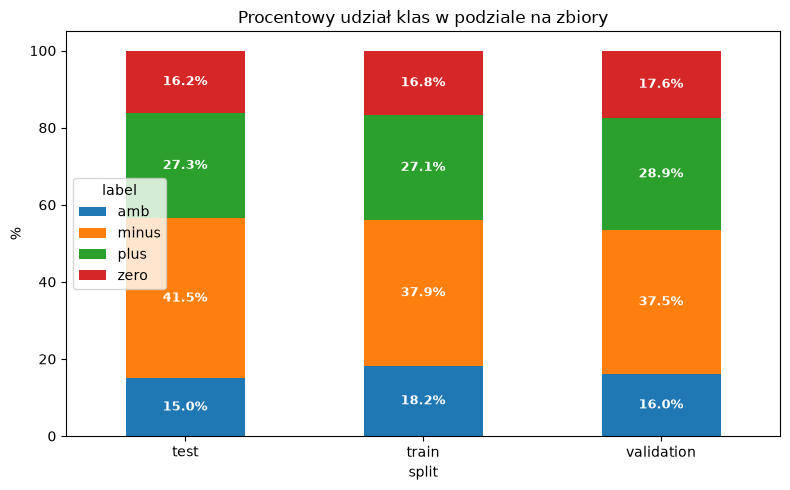

In [22]:
pivot_df = distribution_df.pivot(
    index="split", columns="label", values="percentage"
)
pivot_df = pivot_df.map(lambda x: float(x.replace("%", "")))

ax = pivot_df.plot(kind="bar", stacked=True, figsize=(8, 5), rot=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold", fontsize=9)

plt.ylabel("%")
plt.title("Procentowy udział klas w podziale na zbiory")
plt.tight_layout()
plt.show()

> **Odpowiedzi na pytania:**
>
> 1. Samo accuracy nie będzie wystarczające. Co prawda nie są to zbiory bardzo niezbalansowane, ale jednak zbalansowane też nie są. Modele faworyzujące klasy minus i plus, a nieradzące sobie z zero i amb będą miały całkiem niezłe accuracy, zakłamując nieco rzeczywistość.
>
> 2. Osiągnął by wyniki między 37.5% a 41.5% w zależności od zbioru (mówimy tu o accuracy). 
>
> 3. Rozkłady między splitami są podobne. W każdym splcie minus jest klasą najczęstszą, później plus, natomiast kolejność amb i zero w zbiorze train jest odwrotna do dwóch pozostałych zbiorów, jednak różnice w liczności tych dwóch klas są niewielkie. Widzimy więc, że zbiór danych został podzielony prawidłowo i proporcje klas są zachowane.


# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Dp wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [52]:
all_df = pd.concat(splits.values(), ignore_index=True)

# TODO: do dodania n_chars, n_words, n_words_split, n_lines.

# MIEJSCE NA KOD

all_df["n_chars"] = all_df["sentence"].str.len()
all_df["n_words"] = all_df["sentence"].apply(lambda x: len(re.findall(r"\w+", x)))
all_df["n_words_split"] = all_df["sentence"].apply(lambda x: len(x.split()))
all_df["n_lines"] = all_df["sentence"].apply(lambda x: len(x.splitlines()))
all_df

,sentence,target,split,n_chars,n_words,n_words_split,n_lines
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,__label__meta_plus_m,train,681,105,126,1
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,__label__meta_minus_m,train,663,97,107,1
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",__label__meta_amb,train,304,41,50,1
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",__label__meta_zero,train,917,127,156,1
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,__label__meta_plus_m,train,570,89,109,1
...,...,...,...,...,...,...,...
7223,"Hotel dla ludzi mało wymagających , pokoje w miarę ładne , sprzątane były codziennie , jedynym minusem był grzyb który porastał fugę na długości całej wanny...",__label__meta_minus_m,test,1773,270,322,1
7224,"Zajmowała m pokój w budynku głównym . Standard pozostawia wiele do życzenia . Łazienka jest bardzo mała , nie posiada nawet kabiny prysznicowej , tylko niew...",__label__meta_minus_m,test,1317,182,215,1
7225,W hotelu spędzili śmy uroczy tydzień w marcu . Obsługa była jak zwykle wyjątkowa . Była to już nasza 5 . wizyta i za każdym razem jest coraz lepiej . Ciszej...,__label__meta_plus_m,test,655,107,122,1
7226,Zrobilam wstepna rezerwacje apartamentu z mozliwoscia odwolania . Hotel zrobil preautoryzacje karty a nastepnie autoryzacje - pieniadze sciagneli z konta . ...,__label__meta_minus_m,test,523,73,86,1


In [53]:
# TODO: tabela statystyk długości

# MIEJSCE NA KOD

stats = []
len_columns = ["n_chars", "n_words", "n_words_split", "n_lines"]

for col in len_columns:
    stats.append({
        "feature": col,
        "min": all_df[col].min(),
        "median": all_df[col].median(),
        "mean": round(all_df[col].mean(), 2),
        "p90": np.percentile(all_df[col], 90),
        "p95": np.percentile(all_df[col], 95),
        "p99": np.percentile(all_df[col], 99),
        "max": all_df[col].max()
    })

stats = pd.DataFrame(stats)
stats


,feature,min,median,mean,p90,p95,p99,max
0,n_chars,1,696.0,777.01,1294.0,1605.65,2335.19,5391
1,n_words,1,102.0,114.32,191.0,242.00,352.73,774
2,n_words_split,1,121.0,136.32,228.0,288.65,414.73,987
3,n_lines,1,1.0,1.00,1.0,1.00,1.00,1


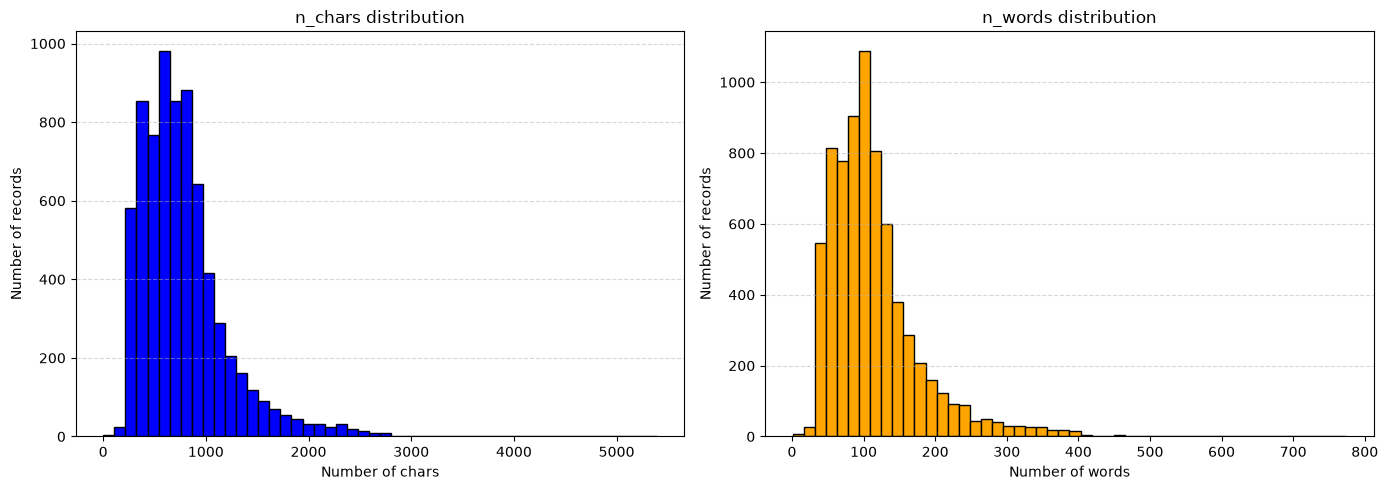

In [54]:
# TODO: histogram długości tekstów

# MIEJSCE NA KOD

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(all_df["n_chars"], bins=50, color="blue", edgecolor="black")
axes[0].set_title("n_chars distribution", fontsize=12)
axes[0].set_xlabel("Number of chars")
axes[0].set_ylabel("Number of records")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].hist(all_df["n_words"], bins=50, color="orange", edgecolor="black")
axes[1].set_title("n_words distribution", fontsize=12)
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Number of records")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [55]:
# TODO: skrajne obserwacje

# MIEJSCE NA KOD

longest_chars = all_df.sort_values(by="n_chars", ascending=False).head(5)
longest_words = all_df.sort_values(by="n_words", ascending=False).head(5)

shortest_chars = all_df.sort_values(by="n_chars").head(5)
shortest_words = all_df.sort_values(by="n_words").head(5)

print("==== 5 longest by chars ====")
for i, (idx, row) in enumerate(longest_chars.iterrows()):
    print(
        f"{i+1} | Chars: {row['n_chars']} | Target: {row['target']}"
    )
    print(f"{repr(row['sentence'])}\n")

print("\n\n==== 5 longest by words ====")
for i, (idx, row) in enumerate(longest_words.iterrows()):
    print(
        f"{i+1} | Words: {row['n_words']} | Target: {row['target']}"
    )
    print(f"{repr(row['sentence'])}\n")

print("\n\n==== 5 shortest by chars ====")
for i, (idx, row) in enumerate(shortest_chars.iterrows()):
    print(
        f"{i+1} | Chars: {row['n_chars']} | Target: {row['target']}"
    )
    print(f"{repr(row['sentence'])}\n")

print("\n\n==== 5 shortest by words ====")
for i, (idx, row) in enumerate(shortest_words.iterrows()):
    print(
        f"{i+1} | Words: {row['n_words']} | Target: {row['target']}"
    )
    print(f"{repr(row['sentence'])}\n")

==== 5 longest by chars ====
1 | Chars: 5391 | Target: __label__meta_minus_m
'Wybór sylwestrowego pakietu w tym hotelu za gigantyczne pieniądze ( jak na zaproponowane warunki i " atrakcje " ) to jeden z naszych największych błędów . Kierowali śmy się reklamami , ogłoszeniami i wizerunkiem hotelu , który kreuje się na mega luksusowy . . . Po 4 godzinach podróży z dzieckiem i kotem otrzymali śmy kartę do pokoju hotelowego . . . Kiedy do niego weszli śmy z wrażenia opadła m na łóżko , zaścielone pomiętą , wygniecioną pościelą . W pokoju . . . brud . Wykładzina poplamiona , w pokoju jedno okno , balkonowe , nieszczelne , problem z otwarciem ( jak wywietrzyć pokój , z jednym balkonowym oknem , którego nie można uchylić , kiedy przyjeżdża się z kotem ? ) na szybach skraplająca się woda , firanki pogniecione , pozaciągane , niedoprane . Stolik nocny z zepsutą szufladą . Abażury lampek mocno po przejściach , ściany obrzydliwie brudne , zaplamione , brak klimatyzacji . No i wisienka na torcie -

> **Obserwacje:**
> 1. n_words_split notuje większe wartości niż n_words, co jest spowodowane faktem, iż w wielu tekstach mamy do czynienia z "dziwną" interpunkcją (znaki interpunkcyjne nie stoją przy wyrazach, ale są oddzielone z obu stron spacjami), która przez split jest traktowana jako osobne wyrazy, a regex nie daje się na to nabrać.
>
> 2. Mediana i średnia są zbliżone, co pozwala stwierdzić że przeciętny tekst ma około 100 znaków. 90 percentyl poniżej 200 znaków też pokazuje, że większość tekstów nie jest przesadnie długa.
>
> 3. Najdłuższe teksty są z reguły ocenami negatywnymi. Zgadza się to z moimi obserwacjami świata rzeczywistego, w którym ludzie są często bardziej wylewni gdy coś im się nie podoba.
>
> 4. Najkrótsze teksty wyglądają na ucięte przed końcem.
>
> 5. Wszystkie obserwacje są jednolinijkowe.

> **Odpowiedzi na pytania:**
>
> 1. Długi tekst nie zawsze jest błędem. Wręcz przeciwnie. Z obserwacji wynika, że długie teksty to wyczerpujące opinie, a najkrótsze to opinie, w któych przydarzył się jakiś błąd.
>
> 2. Klasyczne modele transformerowe mają limity długości wejścia. Za długie teksty mogą zostać obcięte. W batchowaniu, krótsze teksty są uzupełniane paddingiem do długości najdłuższego, co wiąże się z niepotrzebym podbijaniem liczby tokenów. Chunking jest dla długich tekstów rozwiązaniem pozwalającym uniknąć utraty informacji. Później trzeba je złożyć w całość. Ogólnie więc bardzo długie teksty komplikują nieco sprawę.
>
> 3. Jak wspomniałem w obserwacjach, odseparowane znaki interpunkcyjne wpływają na rozbieżności n_words i n_words_split.


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [72]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

def check_uppercase(text, threshold=0.5):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return False
    uppercase_count = sum(1 for c in letters if c.isupper())
    return (uppercase_count / len(letters)) > threshold

punct_burst_regex = r"([!?]\s*){2,}"
url_regex = r"https?://\S+|www\.\S+"
email_regex = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
newline_regex = r"\n|\r"

all_df_noise = all_df.copy()

all_df_noise["has_urls"] = all_df_noise["sentence"].str.contains(url_regex)
all_df_noise["has_emails"] = all_df_noise["sentence"].str.contains(email_regex)
all_df_noise["has_punct_burst"] = all_df_noise["sentence"].str.contains(punct_burst_regex)
all_df_noise["has_newline"] = all_df_noise["sentence"].str.contains(newline_regex)
all_df_noise["is_very_short"] = all_df_noise["sentence"].str.len() < 20
all_df_noise["high_uppercase"] = all_df_noise["sentence"].apply(check_uppercase)

noises = []
noise_cols = ["has_urls", "has_emails", "has_punct_burst", "has_newline", "is_very_short", "high_uppercase"]
for col in noise_cols:
    cnt = all_df_noise[col].sum()
    pct = (cnt / len(all_df_noise)) * 100
    noises.append({"flag": col, "count": cnt, "percentage": f"{pct:.2f}%"})

noises = pd.DataFrame(noises)
noises

C:\Users\szymo\AppData\Local\Temp\ipykernel_21056\536347838.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  all_df_noise["has_punct_burst"] = all_df_noise["sentence"].str.contains(punct_burst_regex)


,flag,count,percentage
0,has_urls,9,0.12%
1,has_emails,0,0.00%
2,has_punct_burst,808,11.18%
3,has_newline,0,0.00%
4,is_very_short,1,0.01%
5,high_uppercase,10,0.14%


> **Obserwacje:**
>
> Flaga *has_punct_burst* występuje stosunkowo często, bo aż w ponad 11% przypadków. Pozostałe zdarzają się sporadycznie lub wcale. Aby *high_uppercase* wzrosło do okolic 1% trzeba obniżyć threshold aż do 0.1. W drugą stronę za to, zwiększanie thresholdu nie zmienia wyniku. Nawet dla 0.9 mamy wciąż 10 rekordów spełniających warunek, dla 0.99 jest 8 takich rekordów. Oznacza to, że te kilka opini jest niezwykle bogatych w pytajniki i wykrzykniki, a zdecydowana większość jest pod tym względem stonowana.

In [76]:
target_noise = (
    all_df_noise.groupby("target")[noise_cols]
    .mean()
    .map(lambda x: f"{x * 100:.2f}%")
)

target_noise

,has_urls,has_emails,has_punct_burst,has_newline,is_very_short,high_uppercase
target,,,,,,
__label__meta_amb,0.00%,0.00%,6.91%,0.00%,0.08%,0.08%
__label__meta_minus_m,0.04%,0.00%,19.57%,0.00%,0.00%,0.18%
__label__meta_plus_m,0.05%,0.00%,8.46%,0.00%,0.00%,0.15%
__label__meta_zero,0.58%,0.00%,0.99%,0.00%,0.00%,0.08%


> **Obserwacje:**
>
> Występuje pewna korelacja między flagą *has_punct_burst* a negatywnymi opiniami. Ma to sens, gdyż ludzie często próbują w ten sposób podkreślić swoje negatywne emocje. Mogłoby do tego sużyć róznież używanie wielkich liter, ale widocznie w tym zbiorze interpunkcja wygrywa. Mimo małych wartości *high_uppercase*, to i tak są one największe dla negatywnych opinii, co tylko podkreśla tezę o potrzebie dobitnego wyrażenia ich. Flaga *has_urls* jest zdecydowanie najbardziej skorelowana z opiniami neutralnymi, co też wydaje się sensowne.
>
> Żadnego z tych zjawisk nie traktowałbym więc jako błąd, a jako sygnały, mogące prowadzić do shortcutów. Należałoby się więc zastanowić, czy warto je zostawić w zbiorach, ponieważ jeśli model nauczy się, że dużo znaków !? oznacza negatywną opinię, może przestać zwracać uwagę na treść, co będzie prowadziło do błędów.


# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [84]:
# TODO:
# preprocessing

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

# MIEJSCE NA KOD

def normalize_text(text):
    if not isinstance(text, str):
        text = str(text) if pd.notna(text) else ""

    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = " ".join(text.split())
    return text.strip()
    

all_df["text_raw"] = all_df["sentence"]
all_df["text_norm"] = all_df["text_raw"].apply(normalize_text)

print("Raw text duplicates", all_df.duplicated("text_raw").sum())
print("Normalized text duplicates", all_df.duplicated("text_norm").sum())

splits_duplicated = (
    all_df.groupby("text_norm")["split"].nunique().loc[lambda x: x > 1]
)
print(f"Texts duplicated between splits: {len(splits_duplicated)}")

Raw text duplicates 0
Normalized text duplicates 0
Texts duplicated between splits: 0


> **Obserwacje:**
> 
> Duplikaty nie występują zarówno w przypadku text_raw jak i w przypadku text_norm. Nie istnieje zatem 10 przykładowych grup duplikatów, ani nie występują duplikaty między splitami.


## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [87]:

def audit_split_leakage(df, text_col="text_norm", split_col="split"):
    # TODO
    leakage_rows = df.groupby(text_col).filter(lambda row: row[split_col].nunique() > 1)
    
    audit_split_leakage = (
        leakage_rows.groupby(text_col)
        .agg(
            count=(text_col, "count"),
            splits=(split_col, lambda x: sorted(x.unique())),
            targets=("target", lambda x: sorted(x.unique()))
        )
        .reset_index()
    )

    return audit_split_leakage


In [88]:
leakage = audit_split_leakage(all_df)
leakage

,text_norm,count,splits,targets


> **Obserwacja:**
>
> Pusty zbiór leakage zgadza się z tym, że duplikaty w naszych danych nie występują.


# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [151]:
# TODO nearest_other_neighbour

# MIEJSCE NA KOD
# j, sim = nearest_other_neighbor(X)
# pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]]

sample_df = all_df.copy()

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
tfidf_matrix = vectorizer.fit_transform(sample_df["text_norm"])

def nearest_other_neighbor(X):
    n_neighbors = NearestNeighbors(n_neighbors=2, metric="cosine", n_jobs=-1)
    n_neighbors.fit(X)
    distances, indices = n_neighbors.kneighbors(X)

    j = indices[:, 1]
    sim = 1.0 - distances[:, 1]

    return j, sim


j, sim = nearest_other_neighbor(tfidf_matrix)

pairs = pd.DataFrame({
    "i": np.arange(len(sample_df)),
    "j": j,
    "split_i": sample_df["split"].values,
    "split_j": sample_df["split"].values[j],
    "similarity": sim,
    "text_i": sample_df["text_norm"].values,
    "text_j": sample_df["text_norm"].values[j]
})

pairs["cross_split"] = sample_df["split"].values[pairs["i"]] != sample_df["split"].values[pairs["j"]]

THRESHOLD = 0.9

similar_pairs = pairs[
    (pairs["similarity"] >= THRESHOLD) & (pairs["i"] < pairs["j"])
].reset_index()

print(f"Same split almost duplicates: {(~similar_pairs['cross_split']).sum()}")
print(f"Cross split almost duplicates: {similar_pairs['cross_split'].sum()}")

Same split almost duplicates: 2
Cross split almost duplicates: 1


In [152]:
similar_pairs

,index,i,j,split_i,split_j,similarity,text_i,text_j,cross_split
0,1344,1344,6642,train,test,0.999948,"„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i h...","„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i h...",True
1,3413,3413,5612,train,train,0.962757,"powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg...","powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg...",False
2,3572,3572,4360,train,train,0.943419,"wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do wojskowej agencji mieszkaniowej . gru...","grupa , która przez chwilę promowała się pod mało rozwojową nazwą hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotel...",False


In [153]:
print(similar_pairs.loc[2, "text_i"])
print(similar_pairs.loc[2, "text_j"])

wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do wojskowej agencji mieszkaniowej . grupa , która przez chwilę promowała się pod mało rozwojową nazwą hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotelu dla nato w bydgoszczy – więcej ) , praktycznie od kilku lat się nie rozwija . nie można tego powiedzieć o louvre hotels group , która wznosi dwa hotele we wrocławiu oraz jest na „ pięć minut ” przez rozpoczęciem inwestycji w bydgoszczy i zielonej górze . dzięki umowie z deweloperską odnogą banku pko bp , firmą qualia development , w ciągu siedmiu lat ma powstać siedem condohoteli pod marką golden tulip residence z ok . tysiącem pokoi , które będą działały na podstawie umów franczyzowych . pierwszy z obiektów , powinien zostać otwarty jeszcze w tym roku w międzyzdrojach . rok 2012 lhg powinna zatem zakończyć z ponad 1 , 5 tys . pokoi . , co ulokuje ją na 5 - 6 pozycji .
grupa , któ

> **Obserwacja**:
> Prawie duplikatów również nie ma wiele. W przypadku tych, które są, widzimy że są to w zasadzie te samo opinie, ale jedna z nich (a może obie) sa ucięte i nie zawierają dokładnie takich samych informacji.


# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [165]:
# MIEJSCE NA KOD

df_oficial = all_df.copy()
df_random = all_df.copy()

train_val_random, test_random = train_test_split(df_random, test_size=0.1, stratify=df_random["target"], random_state=42)
train_random, val_random = train_test_split(train_val_random, test_size=0.1/0.9, stratify=train_val_random["target"], random_state=42)

df_random.loc[train_random.index, "split"] = "train"
df_random.loc[test_random.index, "split"] = "test"
df_random.loc[val_random.index, "split"] = "validation"

random_splits = {
    "train": train_random,
    "validation": val_random,
    "test": test_random
}

distribution_random_splits = []

for split_name, df in splits.items():
    counts = df["target"].value_counts(dropna=False)
    percentages = df["target"].value_counts(normalize=True, dropna=False) * 100

    for label in counts.index:
        mapped_label = LABEL_MAP.get(label)

        distribution_random_splits.append(
            {
                "split": split_name,
                "label": mapped_label,
                "count": counts[label],
                "percentage": f"{percentages[label]:.2f}%"
            }
        )

distribution_random_df = pd.DataFrame(distribution_random_splits)
distribution_random_df

,split,label,count,percentage
0,train,minus,2194,37.94%
1,train,plus,1568,27.11%
2,train,amb,1050,18.16%
3,train,zero,971,16.79%
4,validation,minus,271,37.48%
5,validation,plus,209,28.91%
6,validation,zero,127,17.57%
7,validation,amb,116,16.04%
8,test,minus,300,41.55%
9,test,plus,197,27.29%


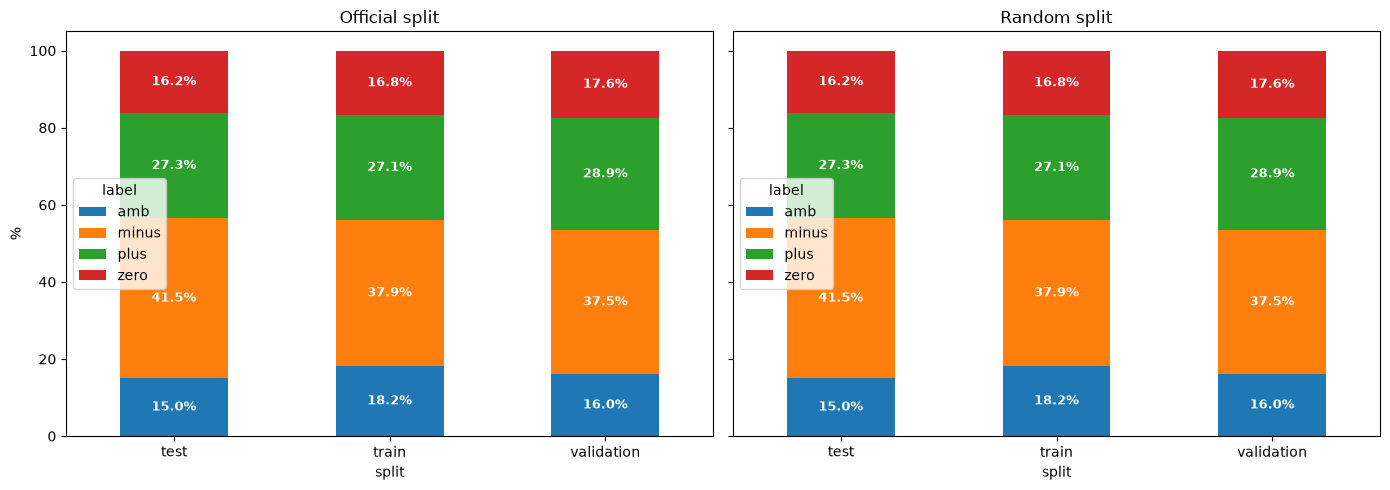

In [166]:
pivot_official = distribution_df.pivot(
    index="split", columns="label", values="percentage"
).map(lambda x: float(str(x).replace("%", "")))

pivot_random = distribution_random_df.pivot(
    index="split", columns="label", values="percentage"
).map(lambda x: float(str(x).replace("%", "")))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

pivot_official.plot(kind="bar", stacked=True, ax=ax1, rot=0)
ax1.set_title("Official split")
ax1.set_ylabel("%")

for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        color="white",
        fontweight="bold",
        fontsize=9,
    )

pivot_random.plot(kind="bar", stacked=True, ax=ax2, rot=0)
ax2.set_title("Random split")

for container in ax2.containers:
    ax2.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        color="white",
        fontweight="bold",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

In [181]:
same_orig_and_random_train = set(train.index).intersection(set(train_random.index))
same_orig_and_random_valid = set(validation.index).intersection(set(val_random.index))
same_orig_and_random_test = set(test.index).intersection(set(test_random.index))

print(f"Same records in train sets in both methods: {len(same_orig_and_random_train)} / {len(train)}")
print(f"Same records in validation sets in both methods: {len(same_orig_and_random_valid)} / {len(validation)}")
print(f"Same records in test sets in both methods: {len(same_orig_and_random_test)} / {len(test)}")

Same records in train sets in both methods: 4634 / 5783
Same records in validation sets in both methods: 68 / 723
Same records in test sets in both methods: 87 / 722


In [180]:
splits_random_duplicated = (
    df_random.groupby("text_norm")["split"].nunique().loc[lambda x: x > 1]
)
print(f"Texts duplicated between splits: {len(splits_duplicated)}")

Texts duplicated between splits: 0


> **Obserwacja**:
> train_test_split ze stratyfikacją dzieli zbiór na części takiej samej wielkości jak części zbioru oryginalnego. Jeśli chodzi o dokładny podział to zbiory nie są dokładnie takie same. Większy zbiór train ma oczywiście więcej duplikatów. Mniejsze zbiory test i validation nie mają aż tak wiele powtórzeń (średnio około 10% ich liczności, czyli proporcja ich liczności do liczności wszystkich danych). Duplikaty tutaj również nie występują.

> **Odpowiedź na pytanie**:
> Losowy split nie zawsze jest poprawnym podejściem. Mimo, że zachowuje odpowiednie proporcje podziału klas w poszczególnych zbiorach, to nie bierze pod uwagę kwestii, które nie są bezpośrednio widoczne w danych, a o których może wiedzieć osoba tworząca podział. W przypadku tego zbioru przy losowym podziale nie zwracamy uwagi na autora wpisu, datę jego wystawienia, żródło itp, a teksty dzielące te cechy mogą być zbliżone stylistycznie, długościowo itd. Jeden człowiek może zwracać uwagę na niedociągnięcia, mimo pozytywej opinii, drugi nie będzie tego robił. W związku z tym robiąc losowy podział możemy doprowadzić do sytuacji, że teksty powiązane ze sobą nie zostaną proporcjonalnie rozdzielone między zbiory.


# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?


> **Hipoteza**:
> 
> Parametry te powinny się poprawić, ponieważ model ucząc się danych testowych jest się w stanie dopasować dokładinie do nich, niejako "ucząc się" nich. Wynik może i się poprawi na zbiorze testowym, ale model traci na generalizacji i na całkowiecie nowych danych prawdopodobnie da gorsze wyniki.

In [176]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["sentence"], train_part["target"])
    pred = probe.predict(test_part["sentence"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }


clean_score = evaluate_probe(train, test)
clean_score


{'accuracy': 0.8365650969529086, 'macro_f1': 0.7965659940906175}

In [179]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["sentence"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train, leaked], ignore_index=True)
    probe.fit(train_leaky["sentence"], train_leaky["target"])
    m = test.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)

,leak_fraction,acc_all,f1_all,acc_leaked,f1_leaked,acc_unleaked,f1_unleaked
0,0.00,0.836565,0.796566,NaN,NaN,0.836565,0.796566
1,0.05,0.837950,0.793777,0.916667,0.824472,0.833819,0.791962
2,0.10,0.839335,0.794763,0.944444,0.903195,0.827692,0.784910
3,0.20,0.855956,0.820547,0.951389,0.934320,0.832180,0.792879
4,0.50,0.889197,0.867642,0.955679,0.945997,0.822715,0.791268
5,1.00,0.958449,0.951080,0.958449,0.951080,NaN,NaN



## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?
2. Czy wynik wzrósł tak mocno, jak było oczekiwane?
3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?
4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?
5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?
6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?

> **Opdowiedzi na pytania**:
>
> 1. Dla wartości leaked różnica była bardzo duża na korzyść większych części zbioru testowego (kilkanaście punktów procentowych). Dla wartości nie leaked różnice były małe z uwagi na proporcje zbiorów treningowego i testowego, ale wyniki jednak się delikatnie pogarszały pokazując (zgodnie z hipotezą) spadek umiejętności generalizacji modelu.
> 2. Tak. Nie oczekiwałem wzrostu do 100%, bo mimo że model widział wszystkie dane testowe to jednak w niektórych przypadkach, zamiast zapamiętywania rolę mogły odegrać rzeczy, których model nauczył się na dużym odsetku danych niepochodzących ze zbioru testowego.
> 3. Ponieważ różne modele są bardziej lub mniej podatne na zapamiętywanie, co zależy od ich mechanizmów uczenia się, pojemności i stosowania regularyzacji.
> 4. Sam wynik nie pozwala ich odróżnić. Dlatego dobrze jest przetestować model na nowym zbiorze danych jeśli daje bardzo dobre wyniki. Jeśli wyniki będą drastycznie gorsze, to prawdopodobnie znaczy, że model się przeuczył.
> 5. Wartoo dodać do pipeline'u sprawdzenie unikalności danych w zbiorach treningowym i testowym. Można też dodać sprawdzenie spójności etykiet dla przypadków tego samego tekstu (jeśli wcześniej tego nie wyczyścilićmy).
> 6. Z zapamiętania wyciekłych rekordów. To dla nich następuje poprawa, która wpływa na ogólny wynik.


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [185]:
# TODO: zdefiniować clean_df zgodnie z polityką czyszczenia

clean_df = all_df.copy()
cleaning_log = []

missing_text = clean_df["text_norm"].isna() | clean_df["text_norm"].astype("string").str.strip().eq("")
missing_target = clean_df["target"].isna() | clean_df["target"].astype("string").str.strip().eq("")
invalid_rows = missing_text | missing_target
cleaning_log.append({"op": "drop_missing_text_or_target", "removed": int(invalid_rows.sum())})
clean_df = clean_df.loc[~invalid_rows].copy()

is_eval = clean_df["split"].isin(["validation", "test"])
clean_df["is_eval_duplicate"] = is_eval & clean_df.duplicated(
    subset=["text_norm"], keep=False
)
cleaning_log.append({
    "op": "flag_duplicates_in_eval",
    "flagged": int(clean_df["is_eval_duplicate"].sum()),
    "removed": 0
})

is_train = clean_df["split"].eq("train")
train_duplicates = is_train & clean_df.duplicated(subset=["text_norm"])
cleaning_log.append({"op": "drop_duplicated_from_train", "removed": int(train_duplicates.sum())})
clean_df = clean_df.loc[~train_duplicates].copy()

other_splits_texts = set(clean_df.loc[clean_df["split"] != "train", "text_norm"])
cross_split_duplicates = clean_df["split"].eq("train") & clean_df["text_norm"].isin(other_splits_texts)
cleaning_log.append({"op": "drop_train_texts_present_in_other_splits", "removed": int(cross_split_duplicates.sum())})
clean_df = clean_df.loc[~cross_split_duplicates].reset_index(drop=True)


cleaning_manifest = pd.DataFrame(cleaning_log)
display(cleaning_manifest)

,op,removed,flagged
0,drop_missing_text_or_target,0,NaN
1,flag_duplicates_in_eval,0,0.0
2,drop_duplicated_from_train,0,NaN
3,drop_train_texts_present_in_other_splits,0,NaN


In [186]:
import sys, sklearn

clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": cleaning_log,
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))

1309

In [188]:
clean_df.groupby("split").size().rename("rows_after_cleaning").to_frame()

,rows_after_cleaning
split,
test,722
train,5783
validation,723


> **Obserwacja**:
> 
> Liczebność zbiorów po czyszczeniu się nie zmieniła.

# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 | bardzo krótki tekst  | "P" | Ciężko z takiego tekstu wyciągnąć odpowiednią etykietę. Model uczy się więc szumu, z którego nic nie wynika |
| 2 | urwany tekst | "Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o" | Z samego początku opinii też nie sposób wyciągnąć odpowiednią etykietę. Nie padły tutaj żadne informacje dotyczące odczuć (nie wiemy czy hotel jest super, czy słabyy jak za tą kwotę) |
| 3 |  |  |  |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.



# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.

> Użytkownik pisze kilka opinii dotyczących tej samej placówki.

### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.

> Sortujemy dane według timestampu i na tej podstawie pierwsze 80% trafia do zbioru treningowego, kolejna 10% do walidacyjnego a ostatnie 10% do testowego.

### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.


In [192]:
def fingerprint(text):
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

clean_df["sha256"] = clean_df["text_norm"].apply(fingerprint)

fp_manifest = {
    "fingerprints": clean_df.groupby("split")["sha256"].apply(list).to_dict(),
}

(ARTIFACTS/"fingerprints_manifest.json").write_text(json.dumps(fp_manifest, indent=2))

534965

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.

In [199]:
similar_pairs_07 = pairs[
    (pairs["similarity"] >= 0.7) & (pairs["similarity"] <= 0.76) & (pairs["i"] < pairs["j"])
].reset_index()

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(similar_pairs_07[["similarity", "text_i", "text_j"]])


,similarity,text_i,text_j
0,0.718419,"częścią projektu jest również stworzenie zaawansowanego systemu informatycznego dla personelu medycznego i dla pacjentów . będzie on zawierał jednolitą bazę danych klinicznych , genetycznych i molekularnych dotyczących dzieci z białaczką , jak również portal informacyjny dla pacjentów . wartość dofinansowania to ponad 13 , 5 mln zł . strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez radę narodowego centrum badań i rozwoju na podstawie krajowego programu badań . dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji polski w perspektywie najbliższych lat . na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne .","w projekcie oprócz śląskiego uniwersytetu medycznego biorą udział : warszawski uniwersytet medyczny , instytut biologii doświadczalnej im . m . nenckiego pan w warszawie , akademia górniczo - hutnicza w krakowie , regionalne centrum naukowo - technologiczne w podzamczu pod kielcami oraz prywatna firma , która ma odpowiadać za wdrożenie wypracowanych rozwiązań . strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez radę narodowego centrum badań i rozwoju na podstawie krajowego programu badań . dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji polski w perspektywie najbliższych lat . na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne ."
1,0.704871,"operacje wszczepienia stymulatorów polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . do tej elektrody przepływa prąd ze stymulatora , który jest umieszczony na tułowiu pacjenta . prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem . stymulator co 15 minut wysyła "" porcję prądu "" do mózgu . prof . maksymowicz tłumaczył wcześniej pap , że ma to wpłynąć na zwiększenie przepływu mózgowego tak , żeby było więcej odżywczej krwi , "" żeby te neurony , które przetrwały u chorych urazy , poczuły się lepiej , były lepiej odżywione ” . zwiększenie przepływu mózgowego i stymulacja mózgu ma w konsekwencji doprowadzić do nawiązania kontaktu z osobami , które dotąd były w stanie minimalnej świadomości .","pionierskie operacje wszczepienia stymulatorów osobom w śpiączkach w maju przeprowadził w olsztyńskim szpitalu klinicznym zespół prof . wojciecha maksymowicza pod kierunkiem japońskiego neurochirurga prof . isao morita ( przeprowadził on w japonii ok . 300 tego rodzaju operacji ) . prof . moritę sprowadziła do polski fundacja ewy błaszczyk "" akogo ? "" , stymulatory dla chorych nieodpłatnie przekazał ich producent - boston scientific polska . operacje polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . do tej elektrody przepływa prąd ze stymulatora , który jest umieszczany na tułowiu pacjentów . prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem ."
2,0.740676,"hotel generalnie ok . czysto i to wystarczy . pokój przestronny . wifi działa przyzwoicie . śniadania w formie szwedzkiego stołu trochę ubogie . parking dodatkowo płatny . z basenu i innych atrakcji nie korzystał em więc nie będę o nich pisać . na jedną noc , biznesowo mogę polecić . pozdrawiam","hotel generalnie ok . czysto i to wystarczy . pokoje nawet przestronne , a w niektórych klimatyzacja . wifi dziala przyzwoicie . śniadania w formie szwedzkiego stołu trochę ubogie ale ni

Opinie te mają pokrywające się fragmenty. Reszta przekazuje to samo ale innymi słowami

In [200]:
similar_pairs_82= pairs[
    (pairs["similarity"] > 0.76) & (pairs["similarity"] <= 0.82) & (pairs["i"] < pairs["j"])
].reset_index()

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(similar_pairs_82[["similarity", "text_i", "text_j"]])

,similarity,text_i,text_j
0,0.786939,"jest bardzo dobrym lekarzem miłu ciepły troszczy się o swoje pacjętki tylko , że ja chodze do niego w gdańsku i nie wiem czy to jest ten sam lekarz ` ` ` ocena została zmieniona na "" polecam "" . powód : zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `","bardzo dobry specjalista ` ` ` ocena została zmieniona na "" polecam "" . powód : zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` ocena została zmieniona na "" polecam "" . powód : zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` ocena została zmieniona na "" polecam "" . powód : zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `"


Tutaj opinie są różne, ale mają wspólne fragmenty "Ocena została zmieniona na polecam..." co podbija wynik similarity.

In [201]:
similar_pairs_88= pairs[
    (pairs["similarity"] > 0.82) & (pairs["similarity"] <= 0.88) & (pairs["i"] < pairs["j"])
].reset_index()

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(similar_pairs_88[["similarity", "text_i", "text_j"]])

,similarity,text_i,text_j


In [202]:
similar_pairs_94= pairs[
    (pairs["similarity"] > 0.88) & (pairs["similarity"] <= 0.94) & (pairs["i"] < pairs["j"])
].reset_index()

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(similar_pairs_94[["similarity", "text_i", "text_j"]])

,similarity,text_i,text_j


In [203]:
similar_pairs_10= pairs[
    (pairs["similarity"] > 0.94) & (pairs["i"] < pairs["j"])
].reset_index()

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(similar_pairs_10[["similarity", "text_i", "text_j"]])

,similarity,text_i,text_j
0,0.999948,"„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .","„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik ."
1,0.962757,"powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w polsce ” . czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . i w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum warszawy , wrocławia czy poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy , gdzie średnio codziennie wynajęte jest 100 pokoi a w hotelu przebywa 120 - 150 gości - nie sposób porównać do 12 - 20 pokojowego hotelu wypoczynkowego , położonego w głębi województwa warmińsko - mazurskiego lub do miejskiego hotelu w niewielkim mieście powiatowym . recepcjonista z dużego wielkomiejskiego hotelu a recepcjonista z małego , lokalnego hotelu - to dwóch różnych pracowników .","powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w polsce ” . czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak ukł

Te opinie są niemal identyczne do siebie. Widzieliśmy je już w zadaniu 6.

In [206]:
duplicates_evaluation = pd.DataFrame({
    "threshold": [0.70, 0.76, 0.82, 0.88, 0.94],
    "n": [3, 1, 0, 0, 3],
    "duplicates": [3, 0, 0, 0, 3],
})

rows = []
for t in duplicates_evaluation["threshold"]:
    sel = duplicates_evaluation[duplicates_evaluation["threshold"] >= t]
    rows.append({"threshold": t, "n": sel["n"].sum(), "precision": sel["duplicates"].sum() / sel["n"].sum() if sel["n"].sum() > 0 else 0})

pd.DataFrame(rows)

,threshold,n,precision
0,0.70,7,0.857143
1,0.76,4,0.750000
2,0.82,3,1.000000
3,0.88,3,1.000000
4,0.94,3,1.000000


> Tylko jeden przypadek wydaje się źle oceniony. Detektor na tym zbiorze radzi sobie dobrze.


# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [ ] sanity check wszystkich splitów;
- [ ] rozkład klas;
- [ ] analizę długości;
- [ ] status zaszumienia;
- [ ] status duplikatów;
- [ ] `audit_split_leakage(...)`;
- [ ] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [ ] porównanie oficjalnego i losowego splitu;
- [ ] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [ ] `artifacts/polemo2_clean.parquet`;
- [ ] `artifacts/splits.json`;
- [ ] `dataset_card.md`;
- [ ] przykłady pomyłek;
- [ ] obserwacje końcowe.